In [27]:
# Import the project root
import sys
import os

project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

print(project_root)

c:\legalmetrica\analisis_encuestas


In [28]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd 
import seaborn as sns

from src.utils import (
                    # uppercase_df_columns_n_content, 
                    uppercase_df_columns_manage_content,
                    preprocess_adt_dataframe, 
                    aggregate_adt_by_transporte
                    )

In [29]:
df_fleet_ice_2505 = pd.read_excel(project_root + '/data_source/vehicle_fleet/Iceberg_Vehicles_Fleet_2507021._OK_2507141.xlsx', sheet_name='ICEBERG', skiprows=0, header=12)  
df_fleet_ice_2505 = df_fleet_ice_2505.iloc[5:,:].reset_index(drop=True)
print(df_fleet_ice_2505.shape)

df_fleet_carg_2505 = pd.read_excel(project_root + '/data_source/vehicle_fleet/Carga_Vehicles_Fleet_2507021 NUEVO.xlsx', sheet_name='CARGA', skiprows=0, header=12)  
df_fleet_carg_2505 = df_fleet_carg_2505.iloc[5:,:].reset_index(drop=True)
print(df_fleet_carg_2505.shape)

df_fleet_tran_2505 = pd.read_excel(project_root + '/data_source/vehicle_fleet/Transer_Vehicles_Fleet_2507021 (002).xlsx', sheet_name='TRANSER-MAYO', skiprows=0, header=12)  
df_fleet_tran_2505 = df_fleet_tran_2505.iloc[5:,:].reset_index(drop=True)
print(df_fleet_tran_2505.shape)

df_fleet_tran_2506 = pd.read_excel(project_root + '/data_source/vehicle_fleet/Transer_Vehicles_Fleet_2507021 (002).xlsx', sheet_name='TRANSER-JUNIO', skiprows=0, header=12)  
df_fleet_tran_2506 = df_fleet_tran_2506.iloc[5:,:].reset_index(drop=True)
print(df_fleet_tran_2506.shape)




c:\legalmetrica\analisis_encuestas\.venv\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)
c:\legalmetrica\analisis_encuestas\.venv\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)
c:\legalmetrica\analisis_encuestas\.venv\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)


(83, 13)
(310, 13)
(419, 13)
(419, 13)


c:\legalmetrica\analisis_encuestas\.venv\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)


In [30]:
# Add supplier period column
df_fleet_ice_2505['SUPPLIER'] = 'ICEBERG'
df_fleet_ice_2505['PERIOD'] = '2505'
df_fleet_ice_2505 = df_fleet_ice_2505.rename(columns={'KM Total Mes Mayo' : 'KM_TOTAL',
                                                      'Consumo Total (GL) Mayo' : 'GL_TOTAL'})

df_fleet_carg_2505['SUPPLIER'] = 'CARGA'
df_fleet_carg_2505['PERIOD'] = '2505'
df_fleet_carg_2505 = df_fleet_carg_2505.rename(columns={'KM Total Mes Mayo' : 'KM_TOTAL',
                                                      'Consumo Total (GL) Mayo' : 'GL_TOTAL'})


df_fleet_tran_2505['SUPPLIER'] = 'TRANSER'
df_fleet_tran_2505['PERIOD'] = '2505'
df_fleet_tran_2505 = df_fleet_tran_2505.rename(columns={'KM Total Mes Mayo' : 'KM_TOTAL',
                                                      'Consumo Total (GL) Mayo' : 'GL_TOTAL'})


df_fleet_tran_2506['SUPPLIER'] = 'TRANSER'
df_fleet_tran_2506['PERIOD'] = '2506'
df_fleet_tran_2506 = df_fleet_tran_2506.rename(columns={'KM Total Mes Junio' : 'KM_TOTAL',
                                                      'Consumo Total (GL) Junio' : 'GL_TOTAL'})


df_fleet_list = [
    df_fleet_ice_2505,
    df_fleet_carg_2505,
    df_fleet_tran_2505,
    df_fleet_tran_2506,
]
df_fleet = pd.concat(df_fleet_list)

display(df_fleet)

,Placa,Marca de Vehículo,Año de Vehículo,Marca de Motor,Referencia Motor,Cilindrada Total,Post – Tratamiento,Combustible,Tecnología Euro,KM_TOTAL,GL_TOTAL,Año de Motor,Notas,SUPPLIER,PERIOD
0,NUV625,SHACMAN,2026.0,CUMMINS,X12,"11,9LT (11900 CC)",SI,DIESEL,IV,3624.0,577.259903,2025.0,NaN,ICEBERG,2505
1,NUV624,SHACMAN,2026.0,CUMMINS,X12,"11,9LT (11900 CC)",SI,DIESEL,IV,3321.0,590.210000,2025.0,NaN,ICEBERG,2505
2,NUV623,SHACMAN,2026.0,CUMMINS,X12,"11,9LT (11900 CC)",SI,DIESEL,IV,2243.0,412.930000,2025.0,NaN,ICEBERG,2505
3,NUV620,SHACMAN,2026.0,CUMMINS,X12,"11,9LT (11900 CC)",SI,DIESEL,IV,4360.0,569.557080,2025.0,NaN,ICEBERG,2505
4,NUV619,SHACMAN,2026.0,CUMMINS,X12,"11,9LT (11900 CC)",SI,DIESEL,IV,4509.0,622.315068,2025.0,NaN,ICEBERG,2505
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
414,XJB062,INTERNATIONAL,2008.0,CUMMINS,ISX 400 ST2,15000.0,NO,DIESEL,II,4411.0,1295.000000,2008.0,NaN,TRANSER,2506
415,XVY006,KENWORTH,2009.0,CUMMINS,ISX 400 ST2,15000.0,NO,DIESEL,II,8650.0,1708.000000,2009.0,NaN,TRANSER,2506
416,XVY014,KENWORTH,2009.0,CUMMINS,ISX 400 ST2,15000.0,NO,DIESEL,II,5000.0,870.000000,2009.0,NaN,TRANSER,2506
417,XVY063,KENWORTH,2009.0,CUMMINS,ISX 400 ST2,15000.0,NO,DIESEL,II,10.0,219.000000,2009.0,NaN,TRANSER,2506


In [31]:
df_fleet.dtypes

Placa                  object
Marca de Vehículo      object
Año de Vehículo       float64
Marca de Motor         object
Referencia Motor       object
Cilindrada Total       object
Post – Tratamiento     object
Combustible            object
Tecnología Euro        object
KM_TOTAL              float64
GL_TOTAL              float64
Año de Motor          float64
Notas                  object
SUPPLIER               object
PERIOD                 object
dtype: object

In [32]:
# Check for null and missing values
print(f"Null values per column:\n{df_fleet.isnull().sum()}")

# Check for duplicate values
print(f"\nNumber of duplicate rows: {df_fleet.duplicated().sum()}")

Null values per column:
Placa                    0
Marca de Vehículo        0
Año de Vehículo          0
Marca de Motor           0
Referencia Motor         0
Cilindrada Total        18
Post – Tratamiento      14
Combustible              0
Tecnología Euro         46
KM_TOTAL                76
GL_TOTAL                76
Año de Motor             0
Notas                 1161
SUPPLIER                 0
PERIOD                   0
dtype: int64

Number of duplicate rows: 0


In [33]:
# Uppercase columns and content
df_fleet = uppercase_df_columns_manage_content(df_fleet)


Shape before potentially dropping columns: (1231, 15)
Shape after dropping empty columns and rows: (1231, 15)
Converting the following columns to string type: ['TRANSPORTE', 'ENTREGA', 'HORA_PLAN_INI', 'HORA_PLAN_FIN', 'HORA_REAL_INI', 'HORA_REAL_FIN', 'CREADO_EL', 'G', 'MATERIAL']
Converting the following columns to float type: ['ADT', 'CALCULO_WPS', 'CANTIDAD_ENTREGA', 'DIF_USD_RED_ID', 'DISTANCIA', 'LIQ_RT', 'N_HL', 'N_KM', 'N_PALLET', 'PALLET', 'PESO_BRUTO', 'PESO_NETO', 'RT_BGT', 'TARIFA_BASE_SIDER', 'TARIFA_BGT', 'TARIFA_DESVIO', 'TARIFA_ESTACA', 'TARIFA_FINAL_REAL', 'V/_NETO', 'VIAJES', 'VIAJES_VIRTUALES', 'VOLUMEN']


In [34]:
df_fleet.columns

Index(['PLACA', 'MARCA_DE_VEHICULO', 'ANO_DE_VEHICULO', 'MARCA_DE_MOTOR',
       'REFERENCIA_MOTOR', 'CILINDRADA_TOTAL', 'POST_TRATAMIENTO',
       'COMBUSTIBLE', 'TECNOLOGIA_EURO', 'KM_TOTAL', 'GL_TOTAL',
       'ANO_DE_MOTOR', 'NOTAS', 'SUPPLIER', 'PERIOD'],
      dtype='object')

In [35]:
# Antes del borrado de celdas NaN hacer un print de la sumatoria de KM_TOTAL_MES_MAYO, CONSUMO_TOTAL_(GL)_MAYO y CONSUMO_TOTAL_(GL)_JUNIO
SUM_KM_MAYO = df_fleet['KM_TOTAL'][df_fleet['PERIOD'] == '2505'].sum()
SUM_GL_MAYO = df_fleet['GL_TOTAL'][df_fleet['PERIOD'] == '2505'].sum()

SUM_KM_JUNIO = df_fleet['KM_TOTAL'][df_fleet['PERIOD'] == '2506'].sum()
SUM_GL_JUNIO = df_fleet['GL_TOTAL'][df_fleet['PERIOD'] == '2506'].sum()

print(
    f"SUMATORIA DE KILÓMETROS DE MAYO: {SUM_KM_MAYO}\n"
    f"SUMATORIA DE CONSUMO (GL) DE MAYO: {SUM_GL_MAYO}\n"
    f"SUMATORIA DE KILÓMETROS DE JUNIO: {SUM_KM_JUNIO}\n"
    f"SUMATORIA DE CONSUMO (GL) DE JUNIO: {SUM_GL_JUNIO}"
)

# Define the key columns on which the cleaning logic will be applied.
KEY_COLUMNS = [
    'KM_TOTAL', 
    'GL_TOTAL'
]

df_fleet.info()

# Se eliminan las columnas vacias
for column in KEY_COLUMNS:
    print(df_fleet.shape)
    df_fleet = df_fleet[~df_fleet[column].isna()]
    df_fleet = df_fleet[df_fleet[column] > 0]
    
    print(df_fleet.shape)    


# Limpiar índice 
df_fleet = df_fleet.reset_index(drop=True)

SUMATORIA DE KILÓMETROS DE MAYO: 3313554.0
SUMATORIA DE CONSUMO (GL) DE MAYO: 622082.4839104263
SUMATORIA DE KILÓMETROS DE JUNIO: 2174437.0
SUMATORIA DE CONSUMO (GL) DE JUNIO: 448672.743823147
<class 'pandas.core.frame.DataFrame'>
Index: 1231 entries, 0 to 418
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   PLACA              1231 non-null   object 
 1   MARCA_DE_VEHICULO  1231 non-null   object 
 2   ANO_DE_VEHICULO    1231 non-null   float64
 3   MARCA_DE_MOTOR     1231 non-null   object 
 4   REFERENCIA_MOTOR   1231 non-null   object 
 5   CILINDRADA_TOTAL   1213 non-null   object 
 6   POST_TRATAMIENTO   1217 non-null   object 
 7   COMBUSTIBLE        1231 non-null   object 
 8   TECNOLOGIA_EURO    1185 non-null   object 
 9   KM_TOTAL           1155 non-null   float64
 10  GL_TOTAL           1155 non-null   float64
 11  ANO_DE_MOTOR       1231 non-null   float64
 12  NOTAS              70 non-nul

In [36]:
# Check for null and missing values
print(f"Null values per column:\n{df_fleet.isnull().sum()}")

# Check for duplicate values
print(f"\nNumber of duplicate rows: {df_fleet.duplicated().sum()}")

Null values per column:
PLACA                   0
MARCA_DE_VEHICULO       0
ANO_DE_VEHICULO         0
MARCA_DE_MOTOR          0
REFERENCIA_MOTOR        0
CILINDRADA_TOTAL       18
POST_TRATAMIENTO       14
COMBUSTIBLE             0
TECNOLOGIA_EURO        46
KM_TOTAL                0
GL_TOTAL                0
ANO_DE_MOTOR            0
NOTAS                1035
SUPPLIER                0
PERIOD                  0
dtype: int64

Number of duplicate rows: 0


In [37]:
# Check for inconsistent values
print(df_fleet.columns)

# Check for outliers
display(df_fleet.describe())

Index(['PLACA', 'MARCA_DE_VEHICULO', 'ANO_DE_VEHICULO', 'MARCA_DE_MOTOR',
       'REFERENCIA_MOTOR', 'CILINDRADA_TOTAL', 'POST_TRATAMIENTO',
       'COMBUSTIBLE', 'TECNOLOGIA_EURO', 'KM_TOTAL', 'GL_TOTAL',
       'ANO_DE_MOTOR', 'NOTAS', 'SUPPLIER', 'PERIOD'],
      dtype='object')


,ANO_DE_VEHICULO,KM_TOTAL,GL_TOTAL,ANO_DE_MOTOR
count,1097.000000,1097.000000,1097.000000,1097.000000
mean,2015.158614,5002.726527,976.075868,2015.098450
std,8.576960,1984.199643,552.560930,8.459185
min,1993.000000,10.000000,2.000000,1993.000000
25%,2008.000000,3730.000000,628.650904,2008.000000
50%,2012.000000,4948.000000,916.000000,2012.000000
75%,2024.000000,6337.000000,1251.000000,2024.000000
max,2026.000000,11042.000000,5424.200278,2026.000000


In [38]:
# Count the number of vehicles by brand
df_fleet.groupby('MARCA_DE_VEHICULO').size().reset_index(name='COUNT')

,MARCA_DE_VEHICULO,COUNT
0,DAF,281
1,FOTON,50
2,FREIGHTLINER,6
3,INTERNATIONAL,255
4,KENWORTH,355
5,MACK,32
6,MERCEDES_BENZ,1
7,SHACMAN,85
8,SINOTRUCK,32


In [39]:
for catego in ['MARCA_DE_VEHICULO', 'MARCA_DE_MOTOR',
       'REFERENCIA_MOTOR', 'CILINDRADA_TOTAL', 'POST_TRATAMIENTO',
       'COMBUSTIBLE', 'TECNOLOGIA_EURO']:
    display(df_fleet.groupby(catego).size().reset_index(name='count'))

,MARCA_DE_VEHICULO,count
0,DAF,281
1,FOTON,50
2,FREIGHTLINER,6
3,INTERNATIONAL,255
4,KENWORTH,355
5,MACK,32
6,MERCEDES_BENZ,1
7,SHACMAN,85
8,SINOTRUCK,32


,MARCA_DE_MOTOR,count
0,CUMMINS,640
1,DETROIT,69
2,MACK,32
3,MERCEDES_BENZ,1
4,PACCAR,323
5,SINOTRUCK,32


,REFERENCIA_MOTOR,count
0,BICAM350,2
1,ISGE5-460,46
2,ISX,113
3,ISX_400_ST2,174
4,ISX_435_ST2,214
5,ISX_475_ST2,2
6,ISZ,20
7,MP-8-445,32
8,MT13.43-50,32
9,MX13,323


,CILINDRADA_TOTAL,count
0,"11,9LT_(11900_CC)",63
1,11800.0,42
2,11946.0,1
3,"12,9LT(12971_CC)",20
4,12400.0,32
5,12700.0,69
6,12800.0,30
7,12900.0,285
8,13000.0,42
9,15000.0,495


,POST_TRATAMIENTO,count
0,NO,595
1,SI,488


,COMBUSTIBLE,count
0,DIESEL,1065
1,GAS_(GNV),32


,TECNOLOGIA_EURO,count
0,I,2
1,II,452
2,III,111
3,IV,63
4,V,171
5,VI,252


In [40]:
df_fleet.groupby(['TECNOLOGIA_EURO', 'REFERENCIA_MOTOR']).size().reset_index(name='COUNT')

,TECNOLOGIA_EURO,REFERENCIA_MOTOR,COUNT
0,I,MX13,2
1,II,ISX_400_ST2,174
2,II,ISX_435_ST2,206
3,II,ISX_475_ST2,2
4,II,OM-541-925,1
5,II,SERIE_60_DDEC_III,19
6,II,SERIE_60_DDEC_IV,50
7,III,ISX,111
8,IV,X12,63
9,V,ISGE5-460,44


In [41]:
df_fleet.groupby(['ANO_DE_MOTOR', 'REFERENCIA_MOTOR']).size().reset_index(name='COUNT')

,ANO_DE_MOTOR,REFERENCIA_MOTOR,COUNT
0,1993.0,BICAM350,2
1,1996.0,SERIE_60_DDEC_III,5
2,1997.0,SERIE_60_DDEC_III,4
3,1998.0,SERIE_60_DDEC_III,10
4,2003.0,ISX_400_ST2,2
5,2003.0,SERIE_60_DDEC_IV,20
6,2004.0,ISX_400_ST2,24
7,2004.0,ISX_435_ST2,4
8,2004.0,SERIE_60_DDEC_IV,30
9,2005.0,ISX_400_ST2,64


In [42]:
# Create column with balanced indicator of km and fuel consumption
df_fleet['KM_PER_GL'] = df_fleet['KM_TOTAL'] / df_fleet['GL_TOTAL']
df_fleet['KM_PER_GL'].describe() 

count    1097.000000
mean        5.807721
std         3.389574
min         0.045662
25%         5.130506
50%         5.378869
75%         6.306751
max        60.452381
Name: KM_PER_GL, dtype: float64

In [43]:
# Take intervals to clasiffy vehicles by balanceado using percentiles
p25 = df_fleet['KM_PER_GL'].quantile(0.25)
p50 = df_fleet['KM_PER_GL'].quantile(0.50)
p75 = df_fleet['KM_PER_GL'].quantile(0.75)

df_fleet['FUEL_EFFICIENCY'] = np.where(df_fleet['KM_PER_GL'] < p25, 'LOW',
                              np.where((df_fleet['KM_PER_GL'] >= p25) & (df_fleet['KM_PER_GL'] < p50), 'MEDIUM_LOW',
                              np.where((df_fleet['KM_PER_GL'] >= p50) & (df_fleet['KM_PER_GL'] < p75), 'MEDIUM_HIGH', 
                              np.where(df_fleet['KM_PER_GL'] >= p75, 'HIGH', ''))))
                                            
                                    
display(df_fleet['FUEL_EFFICIENCY'].value_counts())


FUEL_EFFICIENCY
HIGH           275
MEDIUM_HIGH    274
LOW            274
MEDIUM_LOW     274
Name: count, dtype: int64

In [44]:
df_fleet.head(5)
df_fleet.columns

Index(['PLACA', 'MARCA_DE_VEHICULO', 'ANO_DE_VEHICULO', 'MARCA_DE_MOTOR',
       'REFERENCIA_MOTOR', 'CILINDRADA_TOTAL', 'POST_TRATAMIENTO',
       'COMBUSTIBLE', 'TECNOLOGIA_EURO', 'KM_TOTAL', 'GL_TOTAL',
       'ANO_DE_MOTOR', 'NOTAS', 'SUPPLIER', 'PERIOD', 'KM_PER_GL',
       'FUEL_EFFICIENCY'],
      dtype='object')

In [45]:
df_fleet['MOTOR_REF'] = df_fleet['MARCA_DE_MOTOR'] + '_' + df_fleet['REFERENCIA_MOTOR']
df_fleet['ANO_DE_MOTOR'] = df_fleet['ANO_DE_MOTOR'].astype(int).astype(str)
df_fleet['MOTOR_REF_ANIO'] = df_fleet['MARCA_DE_MOTOR'] + '_' + df_fleet['REFERENCIA_MOTOR'] + '_' + df_fleet['ANO_DE_MOTOR']

In [46]:
# Define the order
fuel_efficiency_order = ['LOW', 'MEDIUM_LOW', 'MEDIUM_HIGH', 'HIGH']

# For REFERENCIA_MOTOR
ctab = pd.crosstab(
    pd.Categorical(df_fleet['FUEL_EFFICIENCY'], categories=fuel_efficiency_order, ordered=True),
    df_fleet['REFERENCIA_MOTOR'],
    rownames=['FUEL_EFFICIENCY']
)
display(ctab)

# For CILINDRADA_TOTAL
ctab = pd.crosstab(
    pd.Categorical(df_fleet['FUEL_EFFICIENCY'], categories=fuel_efficiency_order, ordered=True),
    df_fleet['CILINDRADA_TOTAL'],
    rownames=['FUEL_EFFICIENCY']
)
display(ctab)

# For TECNOLOGIA_EURO
ctab = pd.crosstab(
    pd.Categorical(df_fleet['FUEL_EFFICIENCY'], categories=fuel_efficiency_order, ordered=True),
    df_fleet['TECNOLOGIA_EURO'],
    rownames=['FUEL_EFFICIENCY']
)
display(ctab)

# For MOTOR_REF
ctab = pd.crosstab(
    pd.Categorical(df_fleet['FUEL_EFFICIENCY'], categories=fuel_efficiency_order, ordered=True),
    df_fleet['MOTOR_REF'],
    rownames=['FUEL_EFFICIENCY']
)
display(ctab)

# For MOTOR_REF_ANIO
ctab = pd.crosstab(
    pd.Categorical(df_fleet['FUEL_EFFICIENCY'], categories=fuel_efficiency_order, ordered=True),
    df_fleet['MOTOR_REF_ANIO'],
    rownames=['FUEL_EFFICIENCY']
)
display(ctab)

REFERENCIA_MOTOR,BICAM350,ISGE5-460,ISX,ISX_400_ST2,ISX_435_ST2,ISX_475_ST2,ISZ,MP-8-445,MT13.43-50,MX13,OM-541-925,SERIE_60_DDEC_III,SERIE_60_DDEC_IV,X12,X13EVID560,X15
FUEL_EFFICIENCY,,,,,,,,,,,,,,,,
LOW,0,9,4,40,62,0,0,15,32,89,0,5,14,3,1,0
MEDIUM_LOW,1,14,3,64,82,2,3,6,0,80,0,4,12,1,2,0
MEDIUM_HIGH,1,16,54,38,43,0,3,10,0,65,1,7,12,23,1,0
HIGH,0,7,52,32,27,0,14,1,0,89,0,3,12,36,0,2


CILINDRADA_TOTAL,"11,9LT_(11900_CC)",11800.0,11946.0,"12,9LT(12971_CC)",12400.0,12700.0,12800.0,12900.0,13000.0,15000.0
FUEL_EFFICIENCY,,,,,,,,,,
LOW,3,9,0,0,32,19,15,72,18,103
MEDIUM_LOW,1,11,0,3,0,16,6,70,12,149
MEDIUM_HIGH,23,16,1,3,0,19,9,59,7,131
HIGH,36,6,0,14,0,15,0,84,5,112


TECNOLOGIA_EURO,I,II,III,IV,V,VI
FUEL_EFFICIENCY,,,,,,
LOW,1,118,4,3,52,78
MEDIUM_LOW,0,162,3,1,16,82
MEDIUM_HIGH,1,99,52,23,27,57
HIGH,0,73,52,36,76,35


MOTOR_REF,CUMMINS_BICAM350,CUMMINS_ISGE5-460,CUMMINS_ISX,CUMMINS_ISX_400_ST2,CUMMINS_ISX_435_ST2,CUMMINS_ISX_475_ST2,CUMMINS_ISZ,CUMMINS_X12,CUMMINS_X13EVID560,CUMMINS_X15,DETROIT_SERIE_60_DDEC_III,DETROIT_SERIE_60_DDEC_IV,MACK_MP-8-445,MERCEDES_BENZ_OM-541-925,PACCAR_MX13,SINOTRUCK_MT13.43-50
FUEL_EFFICIENCY,,,,,,,,,,,,,,,,
LOW,0,9,4,40,62,0,0,3,1,0,5,14,15,0,89,32
MEDIUM_LOW,1,14,3,64,82,2,3,1,2,0,4,12,6,0,80,0
MEDIUM_HIGH,1,16,54,38,43,0,3,23,1,0,7,12,10,1,65,0
HIGH,0,7,52,32,27,0,14,36,0,2,3,12,1,0,89,0


MOTOR_REF_ANIO,CUMMINS_BICAM350_1993,CUMMINS_ISGE5-460_2023,CUMMINS_ISGE5-460_2024,CUMMINS_ISX_2007,CUMMINS_ISX_2008,CUMMINS_ISX_2009,CUMMINS_ISX_2012,CUMMINS_ISX_2023,CUMMINS_ISX_400_ST2_2003,CUMMINS_ISX_400_ST2_2004,...,MACK_MP-8-445_2011,MACK_MP-8-445_2024,MERCEDES_BENZ_OM-541-925_2007,PACCAR_MX13_2022,PACCAR_MX13_2023,PACCAR_MX13_2024,PACCAR_MX13_2025,SINOTRUCK_MT13.43-50_2020,SINOTRUCK_MT13.43-50_2021,SINOTRUCK_MT13.43-50_2023
FUEL_EFFICIENCY,,,,,,,,,,,,,,,,,,,,,
LOW,0,0,9,0,0,0,4,0,2,6,...,0,15,0,19,8,59,3,10,8,14
MEDIUM_LOW,1,2,12,0,0,2,1,0,0,9,...,0,6,0,12,10,55,3,0,0,0
MEDIUM_HIGH,1,0,16,1,3,16,32,2,0,5,...,1,9,1,15,10,34,6,0,0,0
HIGH,0,0,7,1,0,23,28,0,0,4,...,1,0,0,41,4,35,9,0,0,0


In [ ]:
def plot_fuel_efficiency_boxplot(df_fleet, fuel_efficiency_order):
    """
    Plots a boxplot of KM_PER_GL by FUEL_EFFICIENCY, colored by TECNOLOGIA_EURO.
    Follows the plotting conventions used in utils.py.
    """
    plt.figure(figsize=(12, 6))
    
    
    # Create the boxplot
    ax = sns.boxplot(
        data=df_fleet,
        x="FUEL_EFFICIENCY",
        y="KM_PER_GL",
        hue='TECNOLOGIA_EURO',
        order=fuel_efficiency_order,
        showfliers=False  # Optionally hide outliers for clarity
    )
    
    # Set axis labels and title
    ax.set_xlabel('Fuel Efficiency Category', fontsize=12)
    ax.set_ylabel('Kilometers per Gallon', fontsize=12)
    ax.set_title('Km per Gl by Fuel Efficiency (Category) and Euro Tech', fontsize=14, fontweight='bold', pad=10)
    
    # Add grid for better readability
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    
    # Adjust legend
    plt.legend(title='TECNOLOGIA_EURO', bbox_to_anchor=(1, 1), loc='upper left')
    
    # Tight layout to prevent overlap
    plt.tight_layout()
    plt.show()


plot_fuel_efficiency_boxplot(df_fleet, fuel_efficiency_order)

### Performance (Km/Gl) by Euro Technology and Fuel Efficiency (OLD)

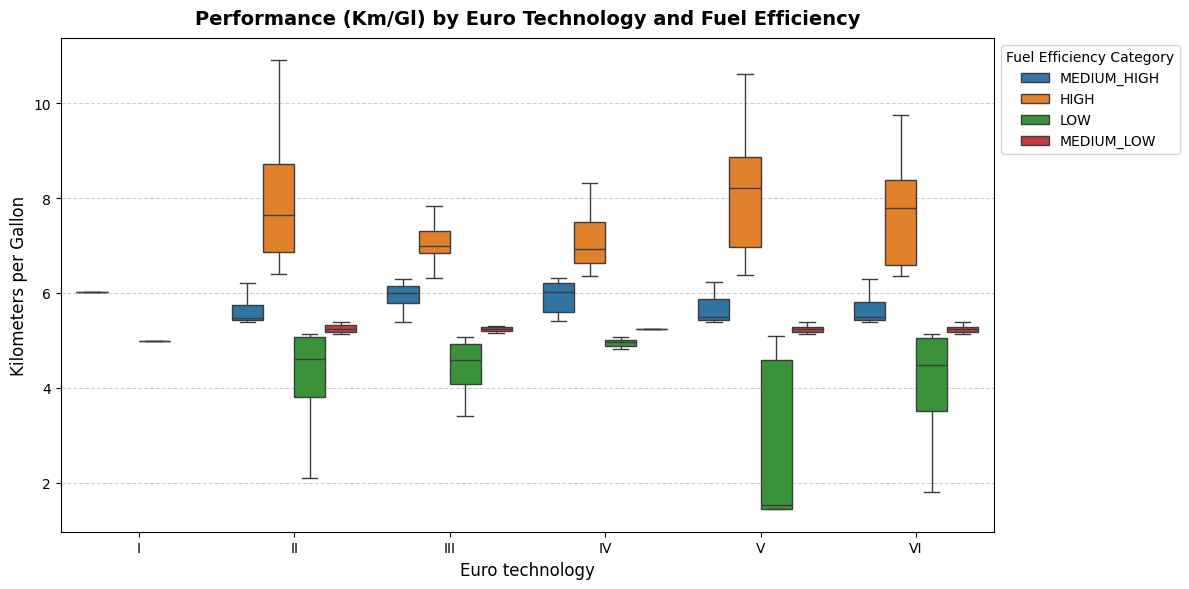

In [47]:
# Define the order
tecnologia_euro_order = ['I', 'II', 'III', 'IV', 'V', 'VI']


def plot_km_per_gl_by_euro_tech(df_fleet, tecnologia_euro_order):
    """
    Graphs the distribution of kilometers per gallon (KM_PER_GL) for each Euro Technology standard, 
    broken down by fuel efficiency category.
    """
    plt.figure(figsize=(12, 6))
    
    
    # Create the boxplot
    ax = sns.boxplot(
        data=df_fleet,
        x="TECNOLOGIA_EURO",
        y="KM_PER_GL",
        hue='FUEL_EFFICIENCY',
        order=tecnologia_euro_order,
        showfliers=False  # Optionally hide outliers for clarity
    )
    
    # Set axis labels and title
    ax.set_xlabel('Euro technology', fontsize=12)
    ax.set_ylabel('Kilometers per Gallon', fontsize=12)
    ax.set_title('Performance (Km/Gl) by Euro Technology and Fuel Efficiency', fontsize=14, fontweight='bold', pad=10)
    
    # Add grid for better readability
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    
    # Adjust legend
    plt.legend(title='Fuel Efficiency Category', bbox_to_anchor=(1, 1), loc='upper left')
    
    # Tight layout to prevent overlap
    plt.tight_layout()
    plt.show()


plot_km_per_gl_by_euro_tech(df_fleet, tecnologia_euro_order)

### Performance (Km/Gl) by Euro Technology and Fuel Efficiency (NEW)

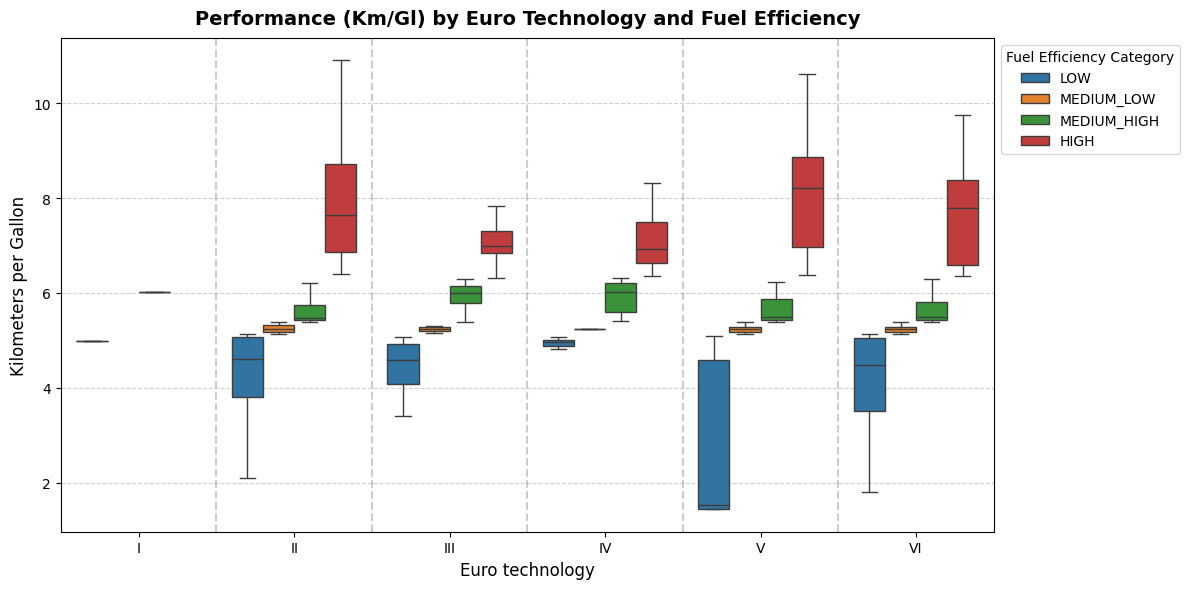

In [48]:
# Define the order
tecnologia_euro_order = ['I', 'II', 'III', 'IV', 'V', 'VI']

def plot_km_per_gl_by_euro_tech(df_fleet, tecnologia_euro_order, fuel_efficiency_order):
    """
    Graphs the distribution of kilometers per gallon (KM_PER_GL) for each Euro Technology standard, 
    broken down by fuel efficiency category.
    """
    plt.figure(figsize=(12, 6))
    
    
    # Create the boxplot
    ax = sns.boxplot(
        data=df_fleet,
        x="TECNOLOGIA_EURO",
        y="KM_PER_GL",
        hue='FUEL_EFFICIENCY',
        order=tecnologia_euro_order,
        showfliers=False,  # Optionally hide outliers for clarity
        hue_order=fuel_efficiency_order,
    )
    
    # Set axis labels and title
    ax.set_xlabel('Euro technology', fontsize=12)
    ax.set_ylabel('Kilometers per Gallon', fontsize=12)
    ax.set_title('Performance (Km/Gl) by Euro Technology and Fuel Efficiency', fontsize=14, fontweight='bold', pad=10)
    
    # Add grid for better readability
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    
    # Add vertical lines for better category separation
    for i in range(len(tecnologia_euro_order) - 1):
        ax.axvline(x=i + 0.5, color='gray', linestyle='--', alpha=0.4)
    
    # Adjust legend
    plt.legend(title='Fuel Efficiency Category', bbox_to_anchor=(1, 1), loc='upper left')
    
    # Tight layout to prevent overlap
    plt.tight_layout()
    plt.show()


plot_km_per_gl_by_euro_tech(df_fleet, tecnologia_euro_order, fuel_efficiency_order)

### Performance (Km/Gl) by Euro Technology and Engine brand - Reference (OLD)

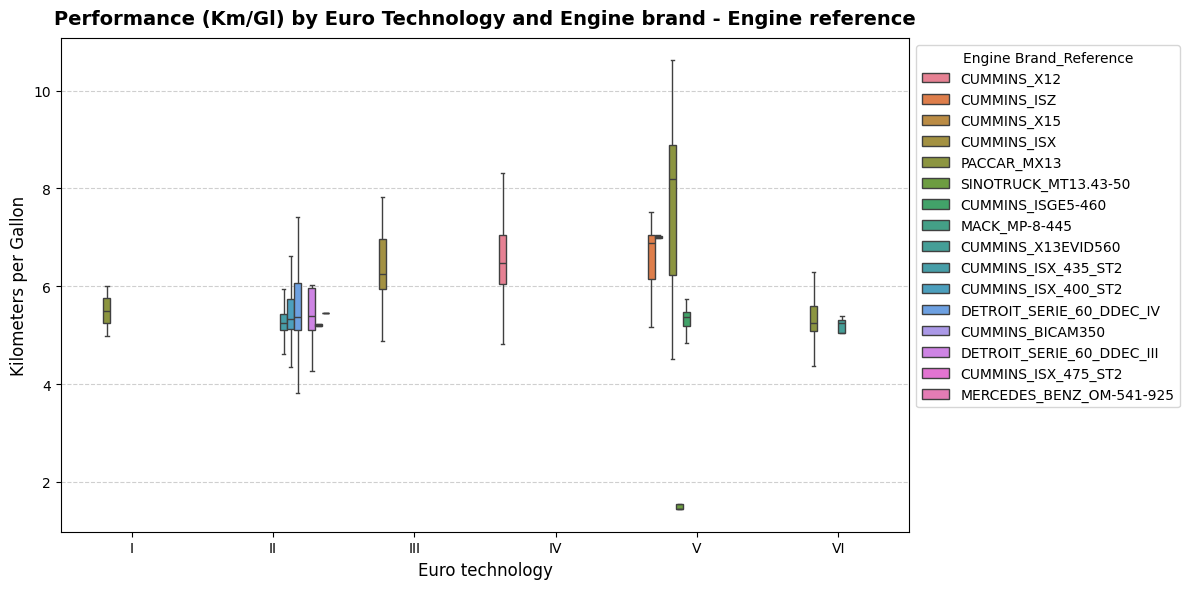

In [49]:
def plot_km_per_gl_by_euro_tech_and_engine_brand_reference(df_fleet, tecnologia_euro_order):
    """
    Plots a boxplot of KM_PER_GL by TECNOLOGIA_EURO, colored by MOTOR_REF_ANIO.
    Follows the plotting conventions used in utils.py.
    """
    plt.figure(figsize=(12, 6))
    
    
    # Create the boxplot
    ax = sns.boxplot(
        data=df_fleet,
        x="TECNOLOGIA_EURO",
        y="KM_PER_GL",
        hue='MOTOR_REF',
        order=tecnologia_euro_order,
        showfliers=False  # Optionally hide outliers for clarity
    )
    
    # Set axis labels and title
    ax.set_xlabel('Euro technology', fontsize=12)
    ax.set_ylabel('Kilometers per Gallon', fontsize=12)
    ax.set_title('Performance (Km/Gl) by Euro Technology and Engine brand - Engine reference', fontsize=14, fontweight='bold', pad=10)
    
    # Add grid for better readability
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    
    # Adjust legend
    plt.legend(title='Engine Brand_Reference', bbox_to_anchor=(1, 1), loc='upper left')
    
    # Tight layout to prevent overlap
    plt.tight_layout()
    plt.show()


plot_km_per_gl_by_euro_tech_and_engine_brand_reference(df_fleet, tecnologia_euro_order)

### Performance (Km/Gl) by Euro Technology and Engine brand - Reference (NEW)

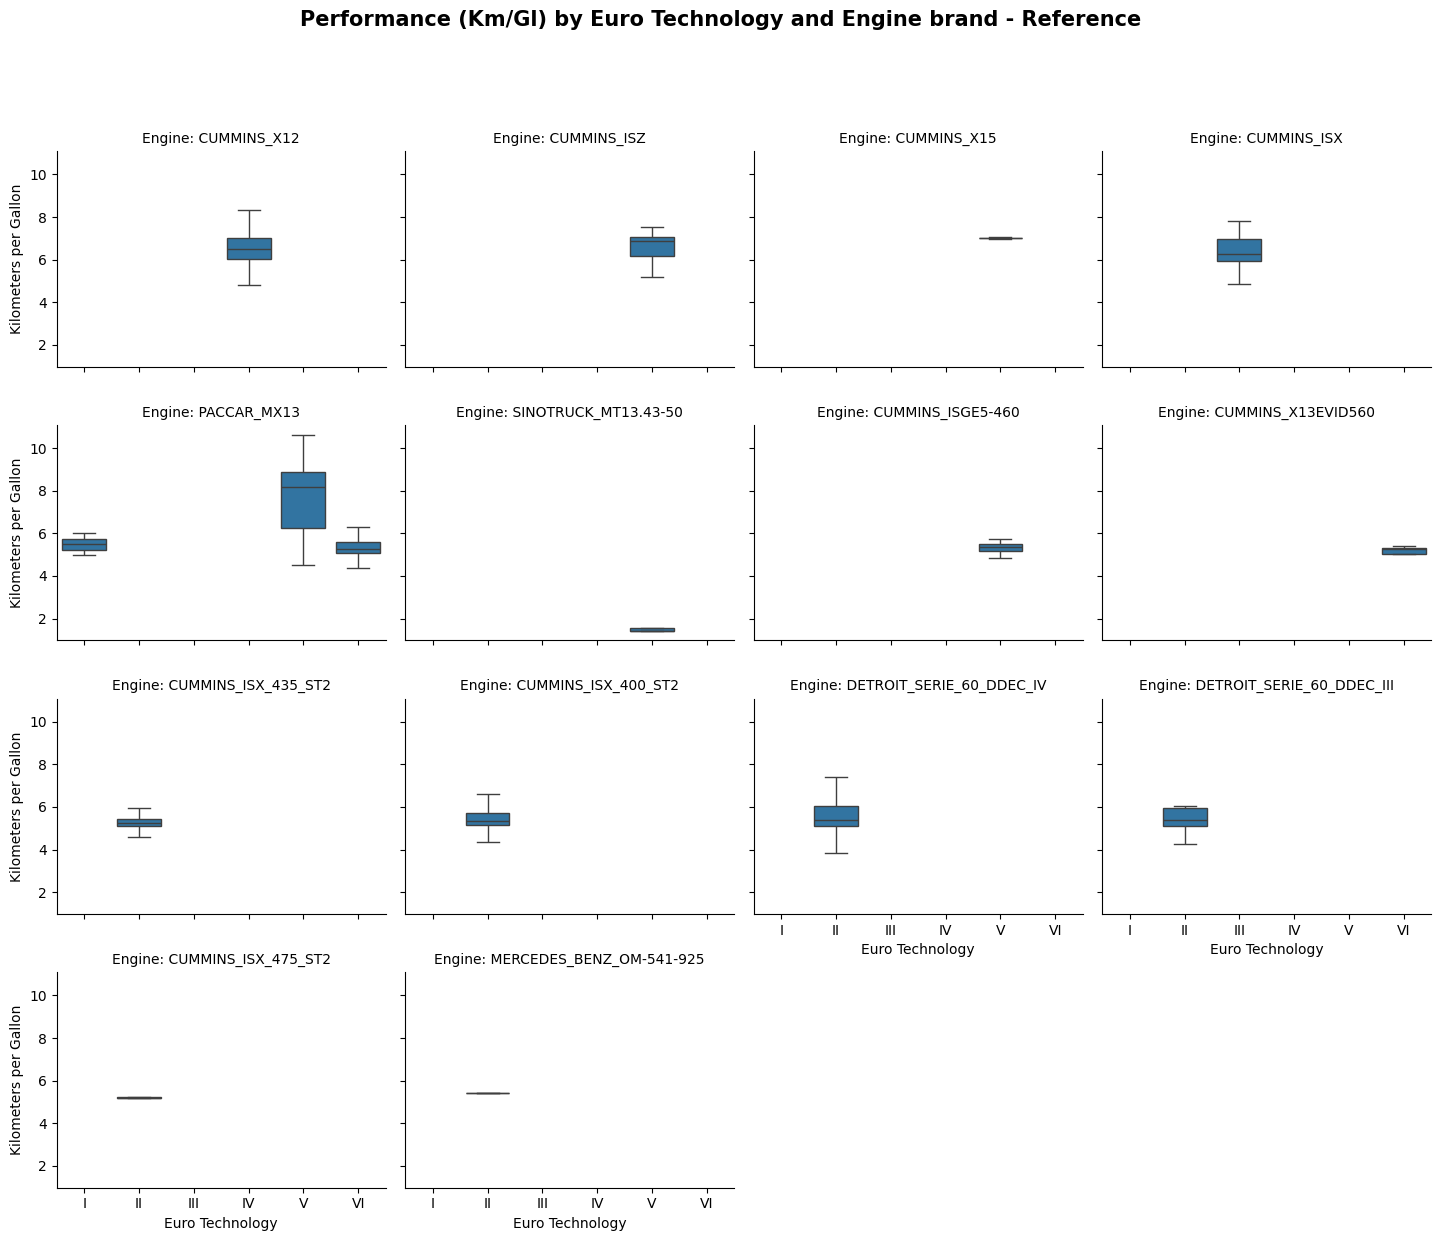

In [50]:
data_fleet = df_fleet.copy()

data_fleet = data_fleet[~data_fleet['TECNOLOGIA_EURO'].isna()]

g = sns.catplot(
    data=data_fleet,
    x="TECNOLOGIA_EURO",
    y="KM_PER_GL",
    col="MOTOR_REF",
    kind="box",      
    order=tecnologia_euro_order,
    col_wrap=4,     
    height=3,   
    aspect=1.2,      
    showfliers=False,
    sharey=True      
)

g.fig.suptitle('Performance (Km/Gl) by Euro Technology and Engine brand - Reference', y=1.03, fontsize=15, fontweight='bold')
g.set_axis_labels("Euro Technology", "Kilometers per Gallon")
g.set_titles("Engine: {col_name}") 

plt.tight_layout(rect=[0, 0, 1, 0.97]) 
plt.show()

### Performance (Km/Gl) by Euro Technology and Engine brand - Reference (NEW2)

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches # Importar para posible chequeo de tipo (aunque no se use en la solución final)
import seaborn as sns
import pandas as pd
import numpy as np

# --- Bloque de ejemplo para crear datos de prueba (igual que antes) ---
np.random.seed(42)
tecnologia_euro_order = ['EURO II', 'EURO III', 'EURO IV', 'EURO V', 'EURO VI']
motor_refs = sorted(['CUMMINS_ISL', 'MERCEDES_OM471', 'SCANIA_DC13', 'VOLVO_D11K'])
data = []
for tech in tecnologia_euro_order:
    for motor in motor_refs:
        if tech == 'EURO IV' and motor == 'SCANIA_DC13':
            continue
        n_points = np.random.randint(10, 20)
        km_gl_data = np.random.normal(loc=15 - len(tech) + motor_refs.index(motor)*1.5, scale=2.5, size=n_points)
        for val in km_gl_data:
            data.append([tech, val, motor])

df_fleet = pd.DataFrame(data, columns=['TECNOLOGIA_EURO', 'KM_PER_GL', 'MOTOR_REF'])
# --------------------------------------------------------------------


def plot_km_per_gl_by_euro_tech_and_engine_brand_reference(df_fleet, tecnologia_euro_order):
    """
    Grafica un boxplot y añade etiquetas rotadas sobre cada caja de forma robusta,
    leyendo los 'artists' del gráfico para evitar errores de alineación y tipo.
    """
    plt.figure(figsize=(18, 10))
    hue_order = sorted(df_fleet['MOTOR_REF'].unique())

    # 1. Dibujar el gráfico CON la leyenda.
    ax = sns.boxplot(
        data=df_fleet,
        x="TECNOLOGIA_EURO",
        y="KM_PER_GL",
        hue='MOTOR_REF',
        order=tecnologia_euro_order,
        hue_order=hue_order,
        showfliers=False
    )

    # 2. Crear un mapa de colores a etiquetas usando la leyenda.
    handles, labels = ax.get_legend_handles_labels()
    color_to_label_map = {h.get_facecolor(): l for h, l in zip(handles, labels)}
    
    x_tick_locations = ax.get_xticks()
    location_to_tech_map = dict(zip(x_tick_locations, tecnologia_euro_order))

    # 3. Iterar sobre `ax.artists`. Esta es la corrección clave.
    # `ax.artists` contiene solo las cajas de colores principales, evitando otros elementos gráficos.
    for artist in ax.artists:
        # Obtener el color de la caja actual
        patch_color = artist.get_facecolor()
        motor_ref_label = color_to_label_map.get(patch_color)
        if not motor_ref_label:
            continue

        # Encontrar la categoría 'TECNOLOGIA_EURO' a la que pertenece la caja
        # Ahora usamos 'artist' en lugar de 'patch'
        patch_x_center = artist.get_x() + artist.get_width() / 2.
        closest_tick_location = min(x_tick_locations, key=lambda x: abs(x - patch_x_center))
        tech_label = location_to_tech_map[closest_tick_location]

        # 4. Calcular la altura del bigote superior
        subset = df_fleet[(df_fleet['TECNOLOGIA_EURO'] == tech_label) & (df_fleet['MOTOR_REF'] == motor_ref_label)]
        if subset.empty:
            continue

        q3 = subset['KM_PER_GL'].quantile(0.75)
        iqr = q3 - subset['KM_PER_GL'].quantile(0.25)
        upper_whisker_limit = q3 + 1.5 * iqr
        whisker_val = subset[subset['KM_PER_GL'] <= upper_whisker_limit]['KM_PER_GL'].max()
        
        y_range = ax.get_ylim()[1] - ax.get_ylim()[0]
        y_pos = whisker_val + (0.015 * y_range)

        # 5. Colocar el texto
        ax.text(patch_x_center, y_pos, motor_ref_label,
                ha='center', va='bottom', rotation=-90, fontsize=10)

    # 6. Limpiar el gráfico
    if ax.get_legend() is not None:
        ax.get_legend().remove()

    ax.set_xlabel('Tecnología Euro', fontsize=12, labelpad=15)
    ax.set_ylabel('Kilómetros por Galón', fontsize=12, labelpad=15)
    ax.set_title('Rendimiento (Km/Gl) por Tecnología Euro y Referencia de Motor', fontsize=16, fontweight='bold', pad=20)
    plt.grid(axis='y', linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.subplots_adjust(top=0.92)

    plt.show()

# Llamar a la función con tus datos
plot_km_per_gl_by_euro_tech_and_engine_brand_reference(df_fleet, tecnologia_euro_order)

### Performance (Km/Gl) by Euro Technology and Engine brand - Reference - Año (OLD)

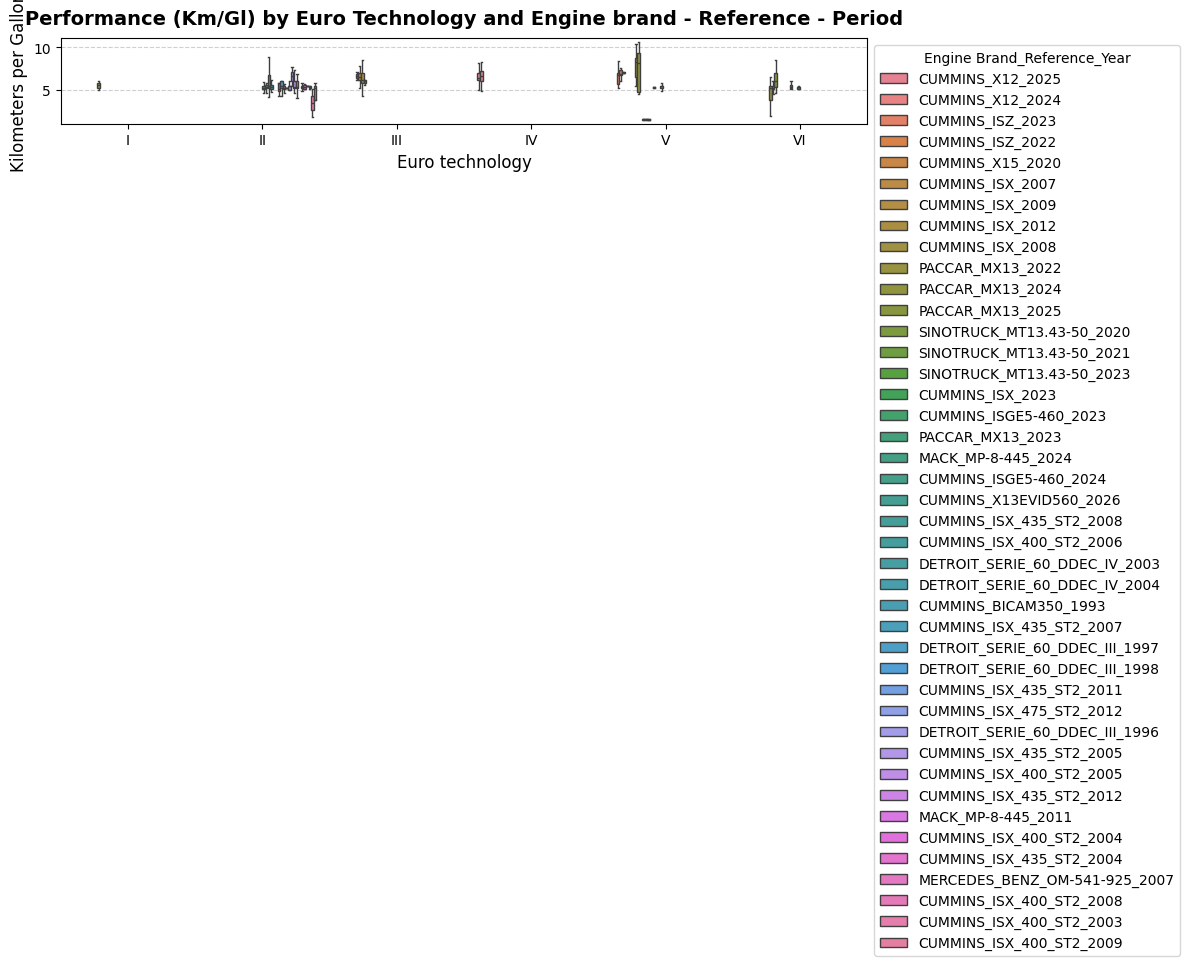

In [51]:
def plot_km_per_gl_by_euro_tech_and_engine_brand_reference_period(df_fleet, tecnologia_euro_order):
    """
    Plots a boxplot of KM_PER_GL by TECNOLOGIA_EURO, colored by MOTOR_REF.
    Follows the plotting conventions used in utils.py.
    """
    plt.figure(figsize=(12, 6))
    
    
    # Create the boxplot
    ax = sns.boxplot(
        data=df_fleet,
        x="TECNOLOGIA_EURO",
        y="KM_PER_GL",
        hue='MOTOR_REF_ANIO',    
        order=tecnologia_euro_order,
        showfliers=False  # Optionally hide outliers for clarity
    )
    
    # Set axis labels and title
    ax.set_xlabel('Euro technology', fontsize=12)
    ax.set_ylabel('Kilometers per Gallon', fontsize=12)
    ax.set_title('Performance (Km/Gl) by Euro Technology and Engine brand - Reference - Period', fontsize=14, fontweight='bold', pad=10)
    
    # Add grid for better readability
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    
    # Adjust legend
    plt.legend(title='Engine Brand_Reference_Year', bbox_to_anchor=(1, 1), loc='upper left')
    
    # Tight layout to prevent overlap
    plt.tight_layout()
    plt.show()


plot_km_per_gl_by_euro_tech_and_engine_brand_reference_period(df_fleet, tecnologia_euro_order)

### Performance (Km/Gl) by Euro Technology and Engine brand - Reference - Año (NEW)

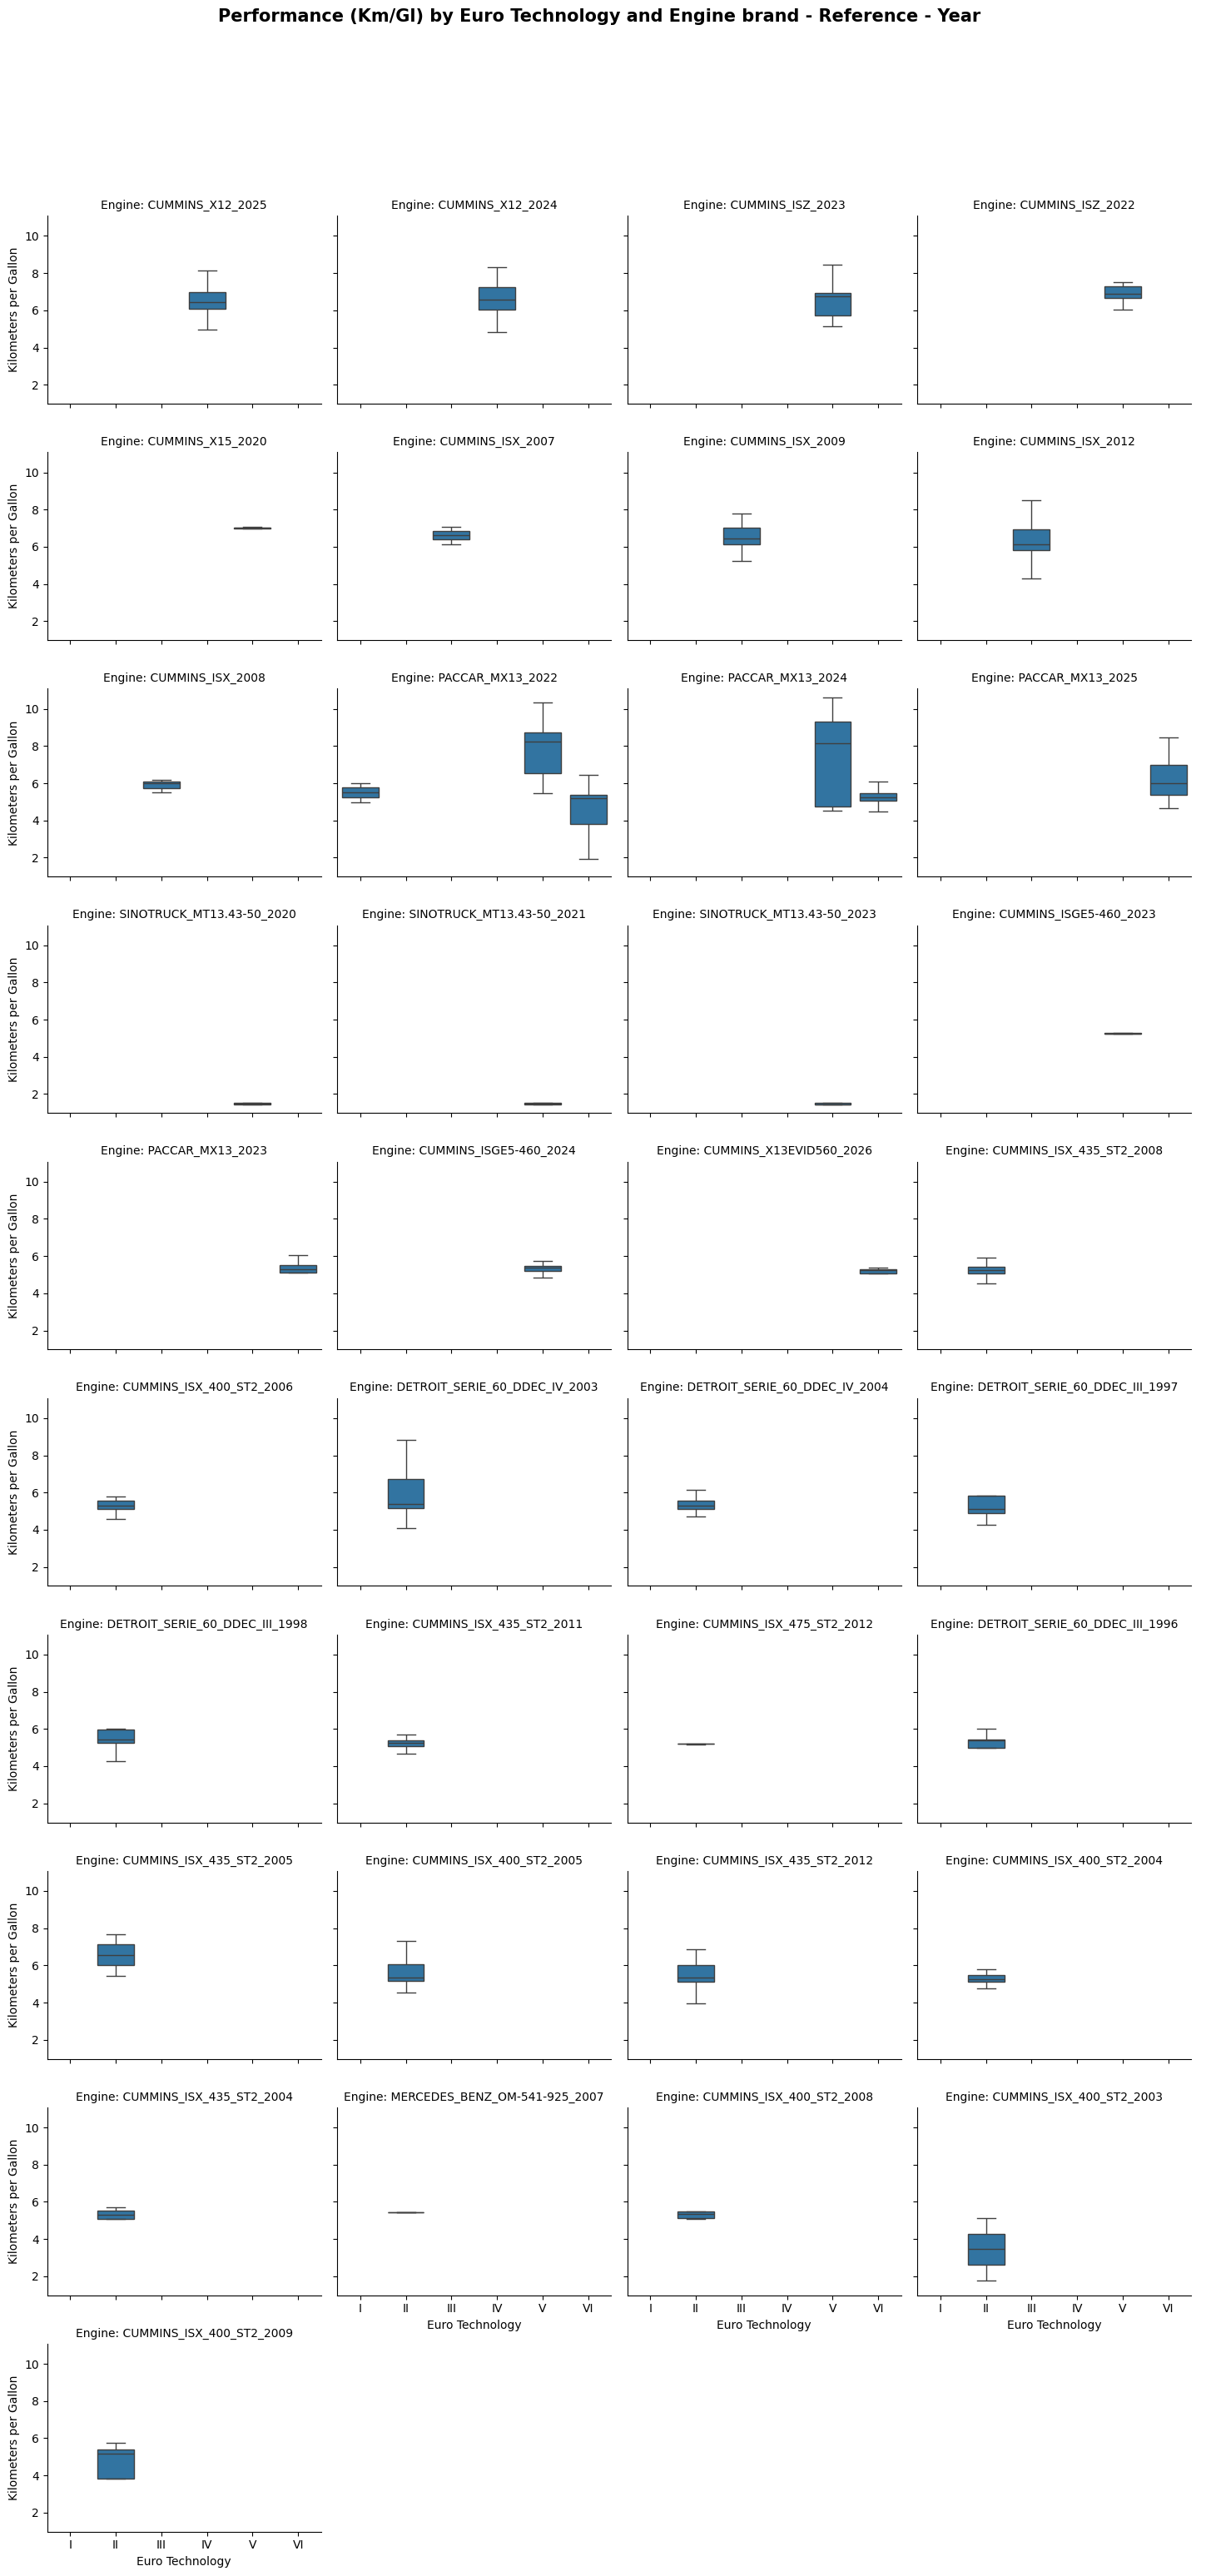

In [52]:
data_fleet = df_fleet.copy()

data_fleet = data_fleet[~data_fleet['TECNOLOGIA_EURO'].isna()]

g = sns.catplot(
    data=data_fleet,
    x="TECNOLOGIA_EURO",
    y="KM_PER_GL",
    col="MOTOR_REF_ANIO",
    kind="box",      
    order=tecnologia_euro_order,
    col_wrap=4,     
    height=3,   
    aspect=1.2,      
    showfliers=False,
    sharey=True      
)

g.fig.suptitle('Performance (Km/Gl) by Euro Technology and Engine brand - Reference - Year', y=1.03, fontsize=15, fontweight='bold')
g.set_axis_labels("Euro Technology", "Kilometers per Gallon")
g.set_titles("Engine: {col_name}") 

plt.tight_layout(rect=[0, 0, 1, 0.97]) 
plt.show()

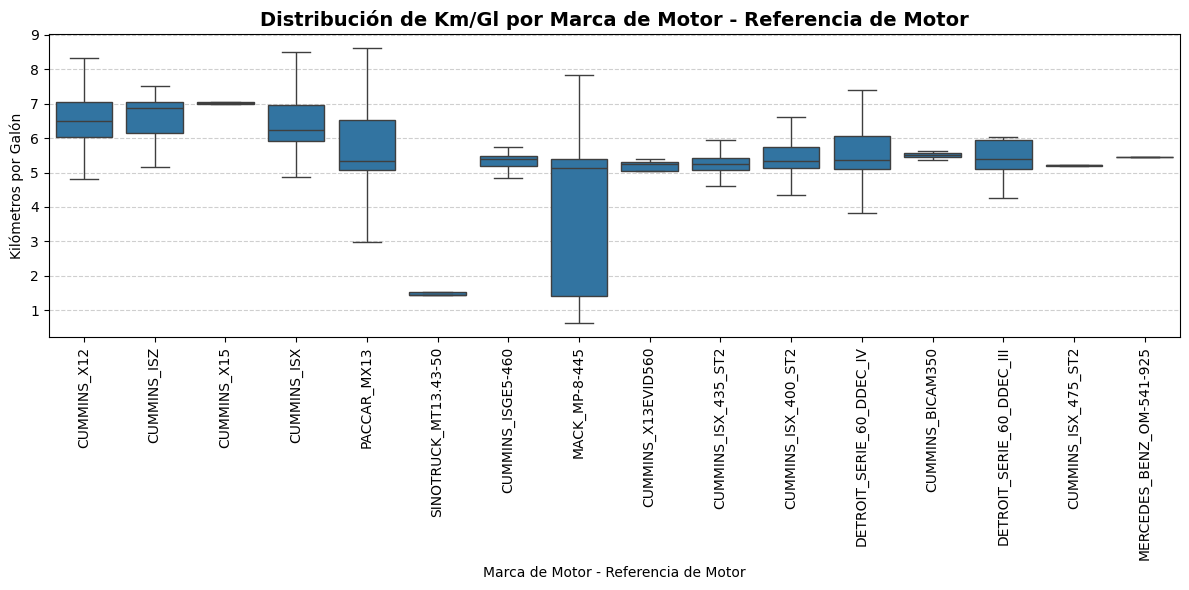

In [53]:
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df_fleet,
    x="MOTOR_REF",
    y="KM_PER_GL",
    showfliers=False  # oculta outliers si quieres más claridad
)
plt.xticks(rotation=90)
plt.title("Distribución de Km/Gl por Marca de Motor - Referencia de Motor", fontsize=14, fontweight="bold")
plt.xlabel("Marca de Motor - Referencia de Motor")
plt.ylabel("Kilómetros por Galón")
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

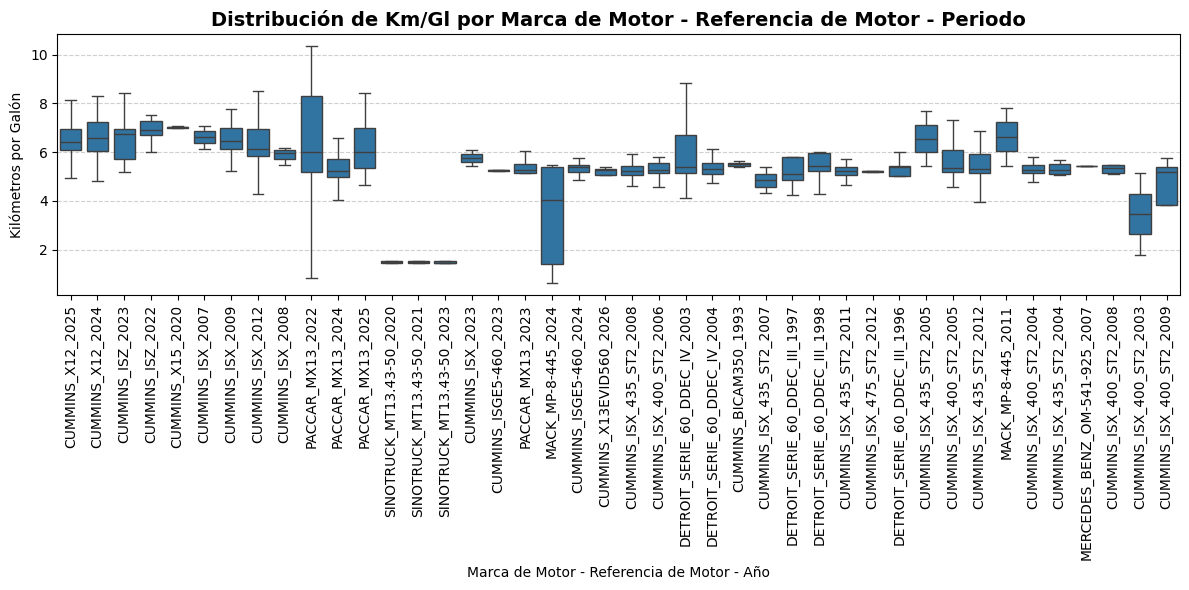

In [54]:
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df_fleet,
    x="MOTOR_REF_ANIO",
    y="KM_PER_GL",
    showfliers=False  # oculta outliers si quieres más claridad
)
plt.xticks(rotation=90)
plt.title("Distribución de Km/Gl por Marca de Motor - Referencia de Motor - Periodo", fontsize=14, fontweight="bold")
plt.xlabel("Marca de Motor - Referencia de Motor - Año")
plt.ylabel("Kilómetros por Galón")
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

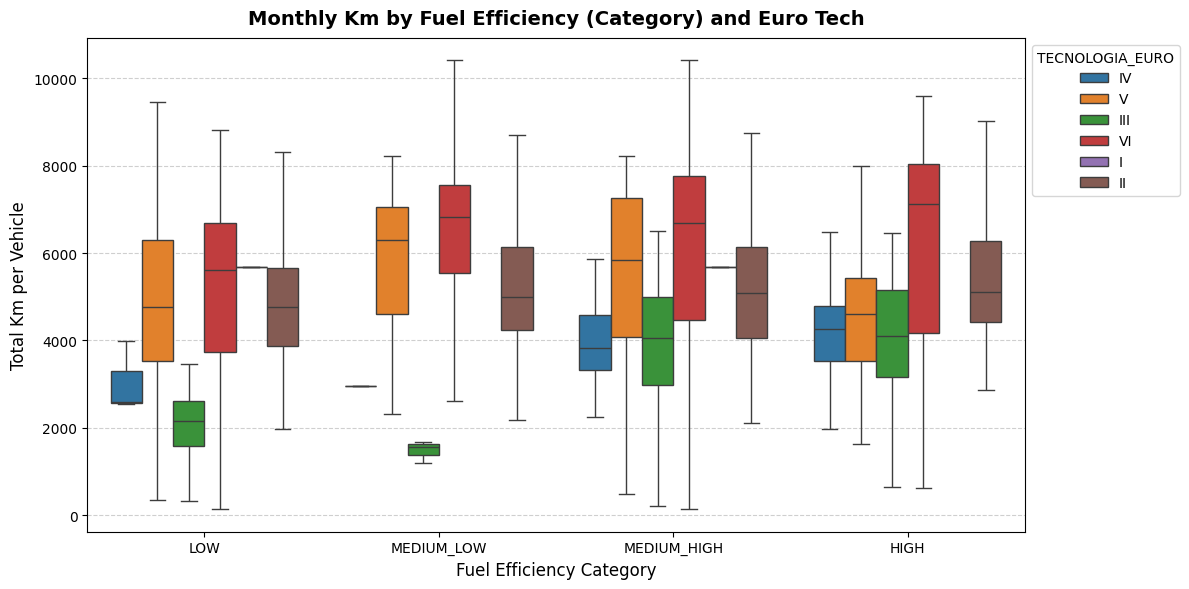

In [55]:
def plot_monthly_kilometers_boxplot(df_fleet, fuel_efficiency_order):
    """
    Plots a boxplot of monthly kilometers by fuel efficiency category and Euro technology.
    """
    plt.figure(figsize=(12, 6))
    ax = sns.boxplot(
        data=df_fleet,
        x="FUEL_EFFICIENCY",
        y="KM_TOTAL",
        hue='TECNOLOGIA_EURO',
        order=fuel_efficiency_order,
        showfliers=False
    )
    ax.set_xlabel('Fuel Efficiency Category', fontsize=12)
    ax.set_ylabel('Total Km per Vehicle', fontsize=12)
    ax.set_title('Monthly Km by Fuel Efficiency (Category) and Euro Tech', 
                fontsize=14, fontweight='bold', pad=10)
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    plt.legend(title='TECNOLOGIA_EURO', bbox_to_anchor=(1, 1), loc='upper left')
    plt.tight_layout()
    plt.show()


plot_monthly_kilometers_boxplot(df_fleet, fuel_efficiency_order)

In [58]:
# Agrupa por 'FUEL_EFFICIENCY' y muestra las 'TECNOLOGIA_EURO' únicas para cada grupo
tecnologias_por_eficiencia = df_fleet.groupby('FUEL_EFFICIENCY')['TECNOLOGIA_EURO'].unique()

print(tecnologias_por_eficiencia)

FUEL_EFFICIENCY
HIGH              [IV, V, III, VI, II, <NA>]
LOW            [IV, III, V, VI, I, II, <NA>]
MEDIUM_HIGH    [IV, V, III, VI, <NA>, II, I]
MEDIUM_LOW        [IV, V, III, VI, <NA>, II]
Name: TECNOLOGIA_EURO, dtype: object


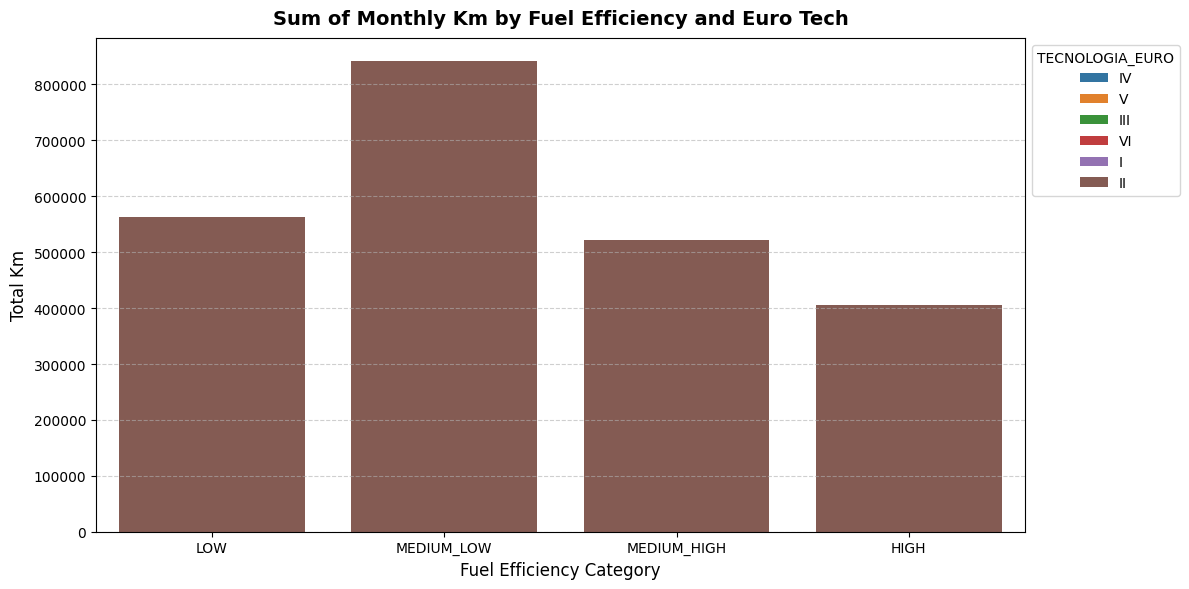

In [57]:
def plot_sum_monthly_kilometers_barplot(df_fleet, fuel_efficiency_order):
    """Barplot of summed monthly km by fuel efficiency and Euro tech."""
    plt.figure(figsize=(12, 6))
    ax = sns.barplot(
        data=df_fleet, 
        x="FUEL_EFFICIENCY", 
        y="KM_TOTAL", 
        hue='TECNOLOGIA_EURO',
        order=fuel_efficiency_order, 
        estimator=sum, 
        errorbar=None,
        dodge=False  # dodge=False stacks the bars
    )
    ax.set_xlabel('Fuel Efficiency Category', fontsize=12)
    ax.set_ylabel('Total Km', fontsize=12)
    ax.set_title('Sum of Monthly Km by Fuel Efficiency and Euro Tech', 
                fontsize=14, fontweight='bold', pad=10)
    # Add grid for better readability
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    plt.legend(title='TECNOLOGIA_EURO', bbox_to_anchor=(1, 1), loc='upper left')
    plt.tight_layout()
    plt.show()
    

plot_sum_monthly_kilometers_barplot(df_fleet, fuel_efficiency_order)

### Anterior (NEW1)

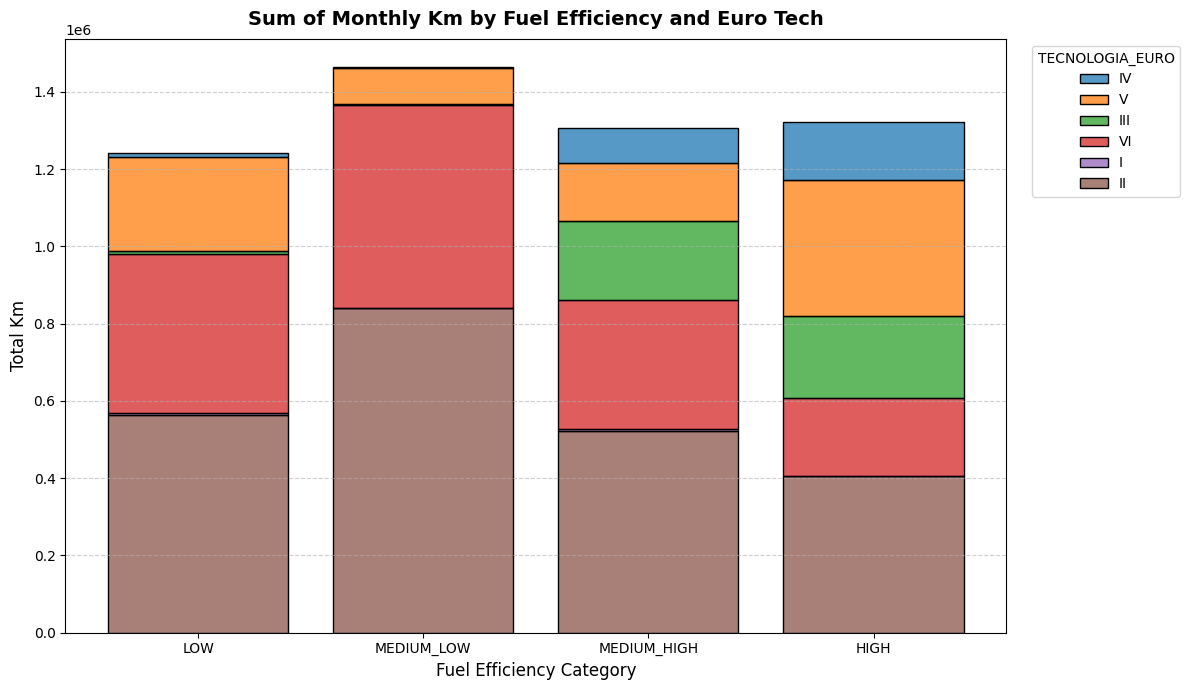

In [63]:
def plot_stacked_sum_monthly_kilometers(df, order_list): 
    """
    Crea un barplot APILADO de la suma de KM mensuales por eficiencia y tecnología Euro.
    Usa histplot, que es la forma correcta de apilar en Seaborn.
    """
    
    # Convertimos la columna del eje X a un tipo categórico con un orden definido.
    # `histplot` respetará este orden automáticamente.
    df['FUEL_EFFICIENCY'] = pd.Categorical(df['FUEL_EFFICIENCY'], categories=order_list, ordered=True)
    
    plt.figure(figsize=(12, 7))

    ax = sns.histplot(
        data=df,
        x="FUEL_EFFICIENCY",
        hue='TECNOLOGIA_EURO',
        weights='KM_TOTAL',
        multiple='stack',
        shrink=0.8
    )

    ax.set_xlabel('Fuel Efficiency Category', fontsize=12)
    ax.set_ylabel('Total Km', fontsize=12)
    ax.set_title('Sum of Monthly Km by Fuel Efficiency and Euro Tech',
                fontsize=14, fontweight='bold', pad=10)

    sns.move_legend(ax, "upper left", bbox_to_anchor=(1.02, 1))

    plt.grid(axis='y', linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

# Definimos el orden deseado
fuel_efficiency_order = ['LOW', 'MEDIUM_LOW', 'MEDIUM_HIGH', 'HIGH']

plot_stacked_sum_monthly_kilometers(df_fleet.copy(), fuel_efficiency_order)

### Anterior (NEW2)

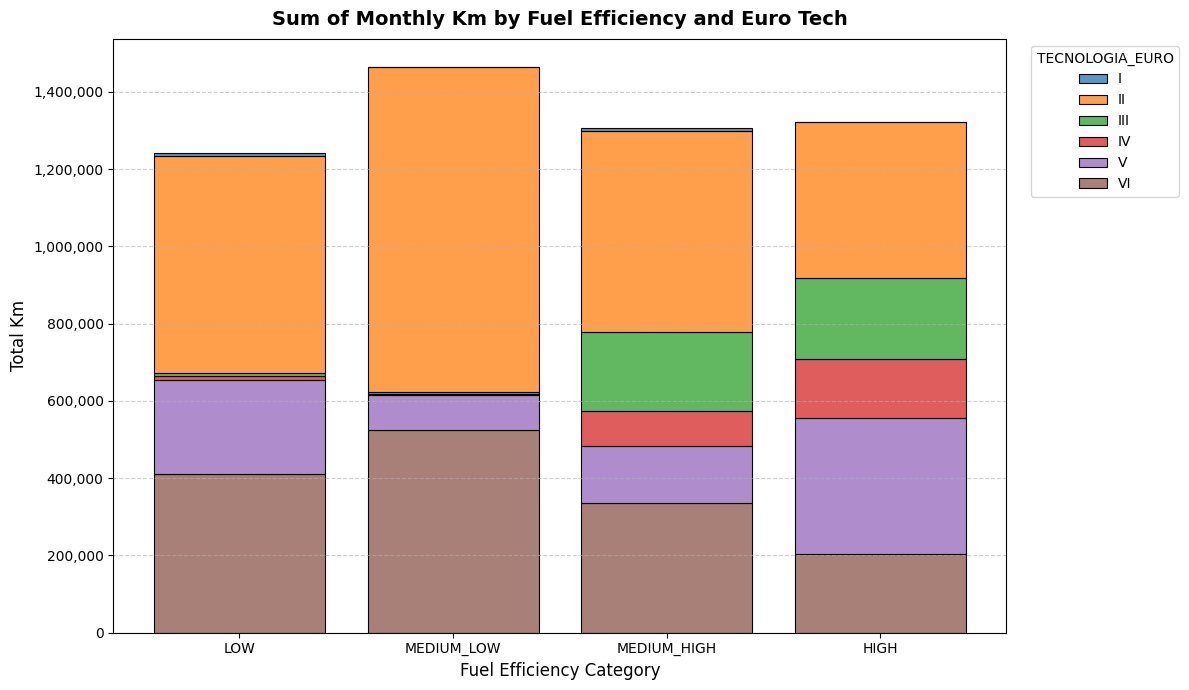

In [71]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

def plot_stacked_sum_monthly_kilometers(df, x_order_list, hue_order_list):
    """
    Creates a STACKED barplot of the sum of monthly KM by fuel efficiency and Euro tech.
    It uses histplot, which is the correct way to stack in Seaborn.
    """

    # We convert the X-axis column to a categorical type with a defined order.
    # `histplot` will respect this order automatically.
    df['FUEL_EFFICIENCY'] = pd.Categorical(df['FUEL_EFFICIENCY'], categories=x_order_list, ordered=True)

    plt.figure(figsize=(12, 7))

    ax = sns.histplot(
        data=df,
        x="FUEL_EFFICIENCY",
        hue='TECNOLOGIA_EURO',
        hue_order=hue_order_list,
        weights='KM_TOTAL',
        multiple='stack',
        shrink=0.8,
        edgecolor="black", # Added to improve the visual separation of the segments
        linewidth=0.8
    )

    ax.set_xlabel('Fuel Efficiency Category', fontsize=12)
    ax.set_ylabel('Total Km', fontsize=12)
    ax.set_title('Sum of Monthly Km by Fuel Efficiency and Euro Tech',
                fontsize=14, fontweight='bold', pad=10)
                
    # KEY MODIFICATION: Format Y-axis to show full numbers instead of scientific notation.
    formatter = mticker.FuncFormatter(lambda x, p: format(int(x), ','))
    ax.yaxis.set_major_formatter(formatter)

    # We get the legend and move it.
    sns.move_legend(ax, "upper left", bbox_to_anchor=(1.02, 1))

    plt.grid(axis='y', linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()


# 1. We define the desired order for the X-axis
fuel_efficiency_order = ['LOW', 'MEDIUM_LOW', 'MEDIUM_HIGH', 'HIGH']

# 2. We define the desired order for the legend
tecnologia_euro_order = ['I', 'II', 'III', 'IV', 'V', 'VI']

# 3. We call the function passing both order lists
plot_stacked_sum_monthly_kilometers(df_fleet.copy(), fuel_efficiency_order, tecnologia_euro_order)

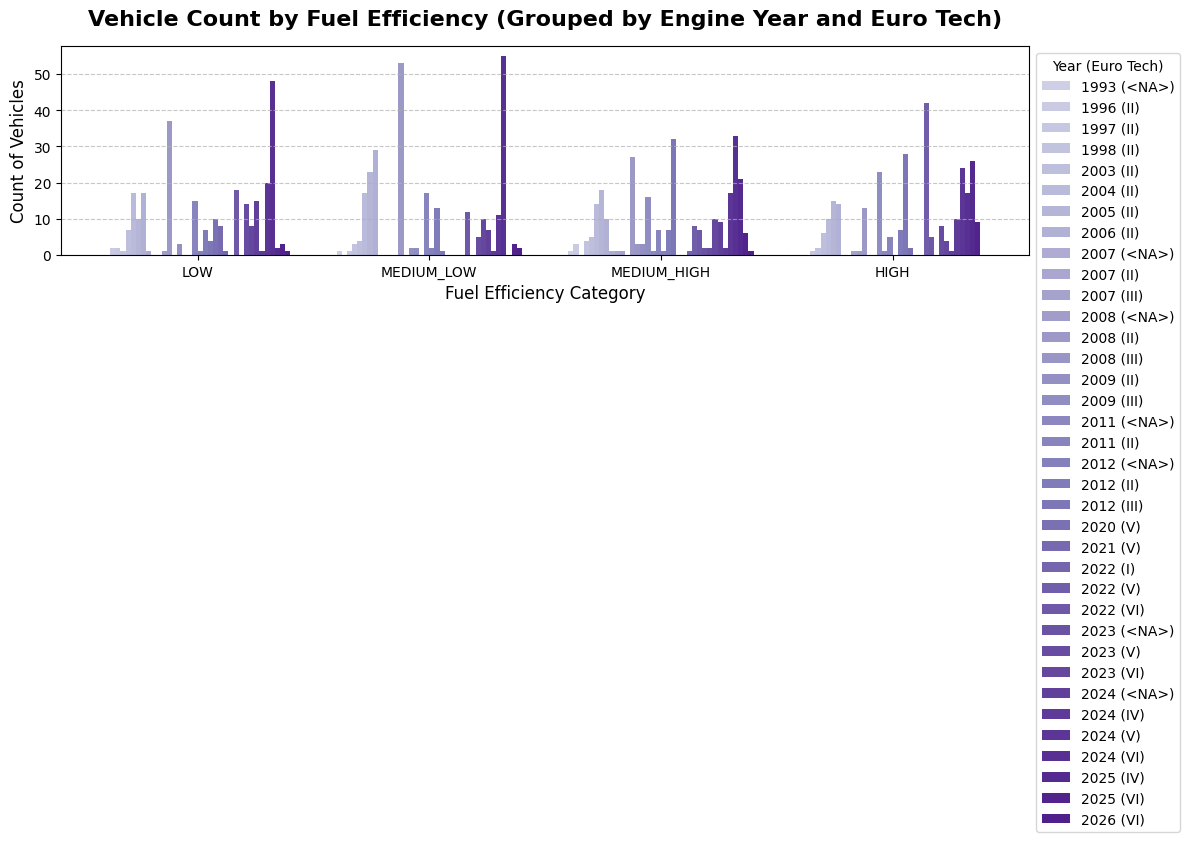

In [65]:
def plot_vehicle_counts_grouped_by_year_and_tech(df_fleet, fuel_efficiency_order):
    """
    Generates a grouped bar chart
    - X-axis: FUEL_EFFICIENCY
    - Groups (side-by-side bars): A combined category of ANO_DE_MOTOR and TECNOLOGIA_EURO.
    """
    
    # Limpiar índice y filtrar categorías inexistentes (new)
    # df_fleet = df_fleet.reset_index(drop=True)
    
    # 1. Create a new, combined category. This will be our grouping variable.
    df_fleet['YEAR_EURO'] = df_fleet['ANO_DE_MOTOR'].astype(str) + \
                           ' (' + df_fleet['TECNOLOGIA_EURO'].astype(str) + ')'
    
    # 2. Define order for x-axis and get a sorted list of our new categories
    group_categories = sorted(df_fleet['YEAR_EURO'].unique())

    # 3. Aggregate data using crosstab. This gets the counts for each combination.
    counts_df = pd.crosstab(index=df_fleet['FUEL_EFFICIENCY'], 
                            columns=df_fleet['YEAR_EURO'])
    
    # Reorder to ensure a consistent plot layout
    counts_df = counts_df.reindex(fuel_efficiency_order, fill_value=0)
    counts_df = counts_df.reindex(group_categories, axis='columns', fill_value=0)

    # 4. Set up the plot and calculate bar dimensions for grouping
    fig, ax = plt.subplots(figsize=(12, 6))
    
    n_groups = len(group_categories)
    x_indices = np.arange(len(fuel_efficiency_order))  # The locations for the groups [0, 1, 2, 3]
    total_width = 0.8  # The total width of the bars for one x-tick
    bar_width = total_width / n_groups

    # Use colormap
    colors = plt.cm.Purples(np.linspace(0.3, 0.9, n_groups))

    # 5. Loop through each group category to plot its bars side-by-side
    for i, category in enumerate(group_categories):
        # Calculate the position for each bar in the group.
        # This calculation centers the group of bars over the x-tick label.
        bar_positions = x_indices - total_width/2 + i * bar_width + bar_width/2
        
        heights = counts_df[category].values
        
        ax.bar(
            bar_positions, 
            heights, 
            width=bar_width, 
            label=category,
            color=colors[i]
        )

    # 6. Customize the plot for clarity
    ax.set_xlabel('Fuel Efficiency Category', fontsize=12)
    ax.set_ylabel('Count of Vehicles', fontsize=12)
    ax.set_title('Vehicle Count by Fuel Efficiency (Grouped by Engine Year and Euro Tech)', 
                 fontsize=16, fontweight='bold', pad=15)
    
    # Set the x-ticks to be in the center of the groups
    ax.set_xticks(x_indices)
    ax.set_xticklabels(fuel_efficiency_order)
    
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    
    # Place the legend outside the plot
    ax.legend(title='Year (Euro Tech)', bbox_to_anchor=(1, 1), loc='upper left')
    
    plt.tight_layout()
    plt.show()


plot_vehicle_counts_grouped_by_year_and_tech(df_fleet, fuel_efficiency_order)

### Kilometros sobre Galón

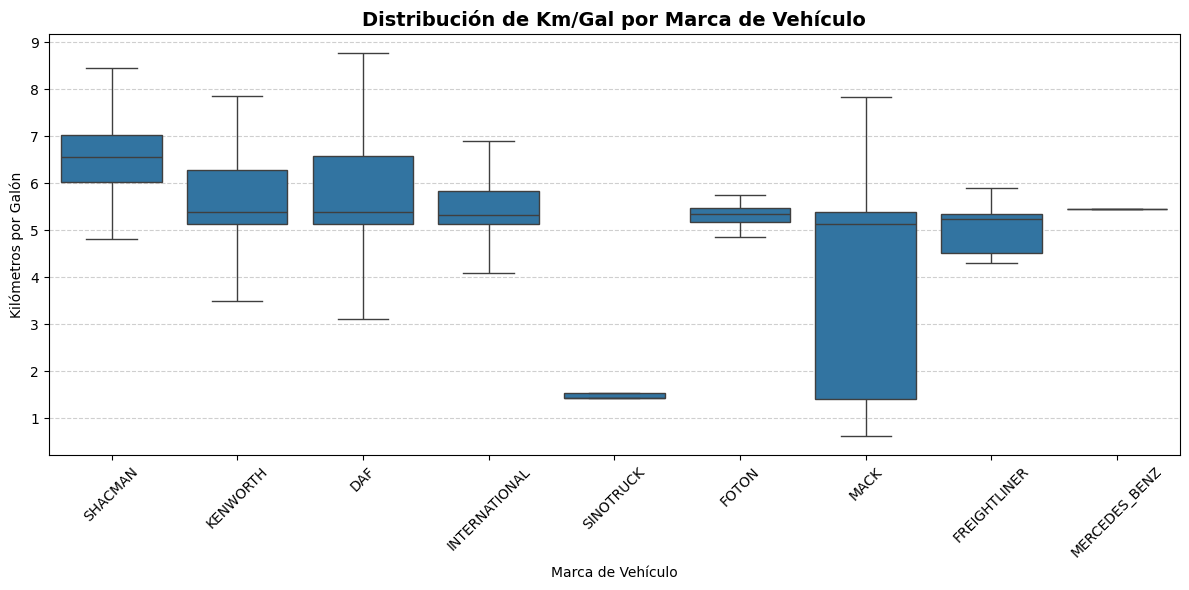

In [66]:
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df_fleet,
    x="MARCA_DE_VEHICULO",
    y="KM_PER_GL",
    showfliers=False  # oculta outliers si quieres más claridad
)
plt.xticks(rotation=45)
plt.title("Distribución de Km/Gal por Marca de Vehículo", fontsize=14, fontweight="bold")
plt.xlabel("Marca de Vehículo")
plt.ylabel("Kilómetros por Galón")
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
# Convert to integer before graphing
df_fleet['ANO_DE_VEHICULO'] = df_fleet['ANO_DE_VEHICULO'].astype(int)

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df_fleet,
    x="ANO_DE_VEHICULO",
    y="KM_PER_GL",
    color="#F28E2B",
    showfliers=False  # oculta outliers si quieres más claridad
)
plt.xticks(rotation=45)
plt.title("Distribución de Km/Gal por Año del Vehículo", fontsize=14, fontweight="bold")
plt.xlabel("Año del Vehículo")
plt.ylabel("Kilómetros por Galón")
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df_fleet,
    x="MARCA_DE_MOTOR",
    y="KM_PER_GL",
    color="#4E79A7",
    showfliers=False  # oculta outliers si quieres más claridad
)
plt.xticks(rotation=0)
plt.title("Distribución de Km/Gl por Marca de Motor", fontsize=14, fontweight="bold")
plt.xlabel("Marca de Motor")
plt.ylabel("Kilómetros por Galón")
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df_fleet,
    x="REFERENCIA_MOTOR",
    y="KM_PER_GL",
    color="#76B7B2",
    showfliers=False  # oculta outliers si quieres más claridad
)
plt.xticks(rotation=45)
plt.title("Distribución de Km/Gal por Referencia de Motor", fontsize=14, fontweight="bold")
plt.xlabel("Referencia de Motor")
plt.ylabel("Kilómetros por Galón")
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df_fleet,
    x="POST_TRATAMIENTO",
    y="KM_PER_GL",
    color="#B07AA1",
    showfliers=False  # oculta outliers si quieres más claridad
)
plt.title("Distribución de Km/Gal por Post Tratamiento", fontsize=14, fontweight="bold")
plt.xlabel("Post Tratamiento")
plt.ylabel("Kilómetros por Galón")
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
# Esta lista le dice a Seaborn exactamente cómo ordenar las categorías.
orden_tecnologia = ['I', 'II', 'III', 'IV', 'V', 'VI'] 

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df_fleet,
    x="TECNOLOGIA_EURO",
    y="KM_PER_GL",
    color="#EDC948",
    showfliers=False,  # oculta outliers si quieres más claridad
    order=orden_tecnologia
)
plt.title("Distribución de Km/Gal por Tecnología EURO", fontsize=14, fontweight="bold")
plt.xlabel("Tecnología EURO")
plt.ylabel("Kilómetros por Galón")
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
# Convert to integer before graphing
df_fleet['ANO_DE_MOTOR'] = df_fleet['ANO_DE_MOTOR'].astype(int)

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df_fleet,
    x="ANO_DE_MOTOR",
    y="KM_PER_GL",
    color="#FF9DA7",
    showfliers=False  # oculta outliers si quieres más claridad
)
plt.xticks(rotation=45)
plt.title("Distribución de Km/Gal por Año del Motor", fontsize=14, fontweight="bold")
plt.xlabel("Año del Motor")
plt.ylabel("Kilómetros por Galón")
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# EXPLORING ADT DATAFRAME

In [ ]:
pd.options.display.max_columns = 1000
df_adt = pd.read_csv(project_root + '/data_source/adt/250531_ADT.csv', sep=',', low_memory=False)#, encoding='latin1')
df_adt = preprocess_adt_dataframe(df_adt)
dict_df_adt = aggregate_adt_by_transporte(df_adt)
df_adt = dict_df_adt['adt_aggregated_all_cols_incl_detour']  # Full dataset including detour

print(f"ADT including detour shape: {dict_df_adt['adt_aggregated_all_cols_incl_detour'].shape}")
print(f"ADT not including detour: {dict_df_adt['adt_aggregated_all_cols_no_detour'].shape}")
df_adt.head()

In [ ]:
# Merge ADT with fleet data
df_adt_fleet = pd.merge(df_adt.loc[df_adt['PLACA'].isin(df_fleet['PLACA']), :], df_fleet.loc[:, ['PLACA', 'FUEL_EFFICIENCY', 'TECNOLOGIA_EURO', 'CONSUMO_TOTAL_(GL)_MAYO']], on='PLACA', how='left')
df_adt_fleet.groupby(['TRANSPORTE', 'PLACA', 'FUEL_EFFICIENCY', 'TECNOLOGIA_EURO']).size().reset_index(name='sum')
df_adt_fleet.head()

In [ ]:
df_adt_fleet_km = (df_adt_fleet.loc[df_adt_fleet['ET_FINAL'] == 'ICEBERG', ['N_KM', 'FUEL_EFFICIENCY']]
                  .groupby(['FUEL_EFFICIENCY'])['N_KM']
                  .agg(['count', 'sum', 'mean', 'std', 'min', 
                        lambda x: x.quantile(0.25), 
                        lambda x: x.quantile(0.50), 
                        lambda x: x.quantile(0.75), 
                        'max'])
                  .rename(columns={'<lambda_0>': '25%', '<lambda_1>': '50%', '<lambda_2>': '75%'})
                  .reindex(fuel_efficiency_order)
                  .reset_index())
print("KM by fuel efficiency")
display(df_adt_fleet_km)

# Analisis de flota de vehiculos por disclosed fuel

In [ ]:
df_fuel_disclosed = pd.read_excel(project_root + '/data_source/disclosed_fuel/2505_analysis_fuel_2506131.xlsx')

# TODO: Include all the preprocessing steps for disclosed fuel, from utils.py
df_fuel_disclosed = df_fuel_disclosed[df_fuel_disclosed['Supplier'] == 'ICEBERG']
df_fuel_disclosed.head()

Discrepancy between two disclosed fuel reports

In [ ]:
display(df_fuel_disclosed[['Supplier', 'Galones']].groupby(['Supplier']).sum())
display(df_fleet['CONSUMO_TOTAL_(GL)_MAYO'].sum())